In [85]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import numpy as np
%matplotlib inline
from sklearn import datasets, linear_model
import pandas as pd
from matplotlib.dates import DateFormatter

In [86]:
dataset = pd.read_csv('bees_austrian_db.csv', parse_dates=['date'])
dataset.head(10)

,date,temperature,humidity,windspeed,weight,winddir
0,2016-07-25 06:45:00,20.1,83.0,0.2,31.66,192
1,2016-07-25 07:00:00,20.4,81.0,0.0,31.71,192
2,2016-07-25 07:15:00,20.7,82.0,0.0,31.71,192
3,2016-07-25 07:30:00,20.8,84.0,0.0,31.66,192
4,2016-07-25 07:45:00,20.8,84.0,0.0,31.64,192
5,2016-07-25 08:00:00,21.8,79.0,0.0,31.57,193
6,2016-07-25 08:15:00,23.3,74.0,2.2,31.50,193
7,2016-07-25 08:30:00,24.0,72.0,4.1,31.42,192
8,2016-07-25 08:45:00,24.6,70.0,0.5,31.40,190
9,2016-07-25 09:00:00,24.7,69.0,1.6,31.38,188


In [87]:
# Replace commas with dots in numeric columns for proper parsing
numeric_columns = ['temperature', 'humidity', 'weight','windspeed', 'winddir']
dataset[numeric_columns] = dataset[numeric_columns].replace(',', '.', regex=True)

# Convert numeric columns to appropriate data types
dataset[numeric_columns] = dataset[numeric_columns].apply(pd.to_numeric, errors='coerce')

# Save the result to a new CSV file
dataset.to_csv('converted_data.csv', index=False)

In [88]:
len(dataset)

15065

In [89]:
#moving average
#dataset resample
#import lstm
dataset.head(5)

,date,temperature,humidity,windspeed,weight,winddir
0,2016-07-25 06:45:00,20.1,83.0,0.2,31.66,192
1,2016-07-25 07:00:00,20.4,81.0,0.0,31.71,192
2,2016-07-25 07:15:00,20.7,82.0,0.0,31.71,192
3,2016-07-25 07:30:00,20.8,84.0,0.0,31.66,192
4,2016-07-25 07:45:00,20.8,84.0,0.0,31.64,192


In [90]:
# Convert the 'datetime' column to datetime type if it's not already

dataset.index = pd.to_datetime(dataset['date'])

# Define aggregation functions for each column
aggregation = {
    'temperature': 'mean', # Take mean instead of sum
    'humidity': 'mean',  # Take mean instead of sum
    'weight': 'mean', # take last weight change of the day which is kind of like taking the sum but without getting NaN values
    'windspeed': 'mean',
    'winddir': 'mean',
}

# Resample to daily frequency and aggregate with different functions
daily_data = dataset.resample('D').agg(aggregation)
#daily_data['weight_change'] = dataset['weight'] #readding weight

daily_data.drop(columns=['weight'], inplace=True)
# Use the cumulative sum of weight for a more accurate result then just using sum:
#daily_data['weight_cumsum'] = daily_data['weight'].cumsum()
dataset.drop(columns=['date'], inplace=True)

print("Original DataFrame:")
print(dataset.head(2))
print("\nDaily aggregated DataFrame:")
print(daily_data.head(2))


Original DataFrame:
                     temperature  humidity  windspeed  weight  winddir
date                                                                  
2016-07-25 06:45:00         20.1      83.0        0.2   31.66      192
2016-07-25 07:00:00         20.4      81.0        0.0   31.71      192

Daily aggregated DataFrame:
            temperature   humidity  windspeed     winddir
date                                                     
2016-07-25    21.077941  86.176471   0.253623  194.405797
2016-07-26    21.259375  83.406250   0.000000  199.739583


In [91]:
daily_data.head(10)

,temperature,humidity,windspeed,winddir
date,,,,
2016-07-25,21.077941,86.176471,0.253623,194.405797
2016-07-26,21.259375,83.406250,0.000000,199.739583
2016-07-27,21.075000,83.885417,0.000000,205.260417
2016-07-28,19.288542,89.177083,0.000000,211.739583
2016-07-29,21.131579,81.094737,0.000000,217.642105
2016-07-30,22.250000,79.760417,0.002083,221.708333
2016-07-31,21.555435,81.500000,0.136458,226.770833
2016-08-01,18.480208,89.229167,0.000000,228.395833
2016-08-02,19.178125,75.687500,0.000000,230.166667


<Axes: >

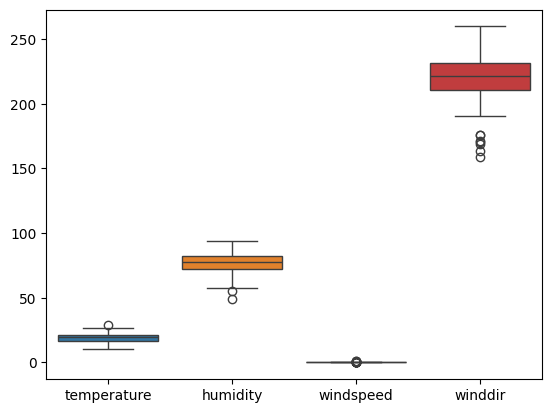

In [92]:
# sns.boxplot(data=daily_data)
sns.boxplot(data=daily_data)

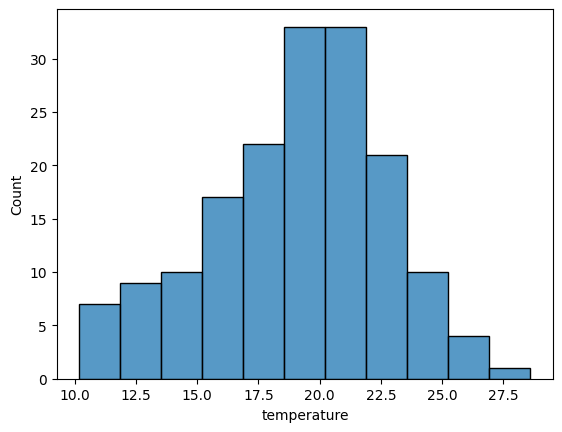

In [93]:
sns.histplot(data=daily_data['temperature'])
plt.show()

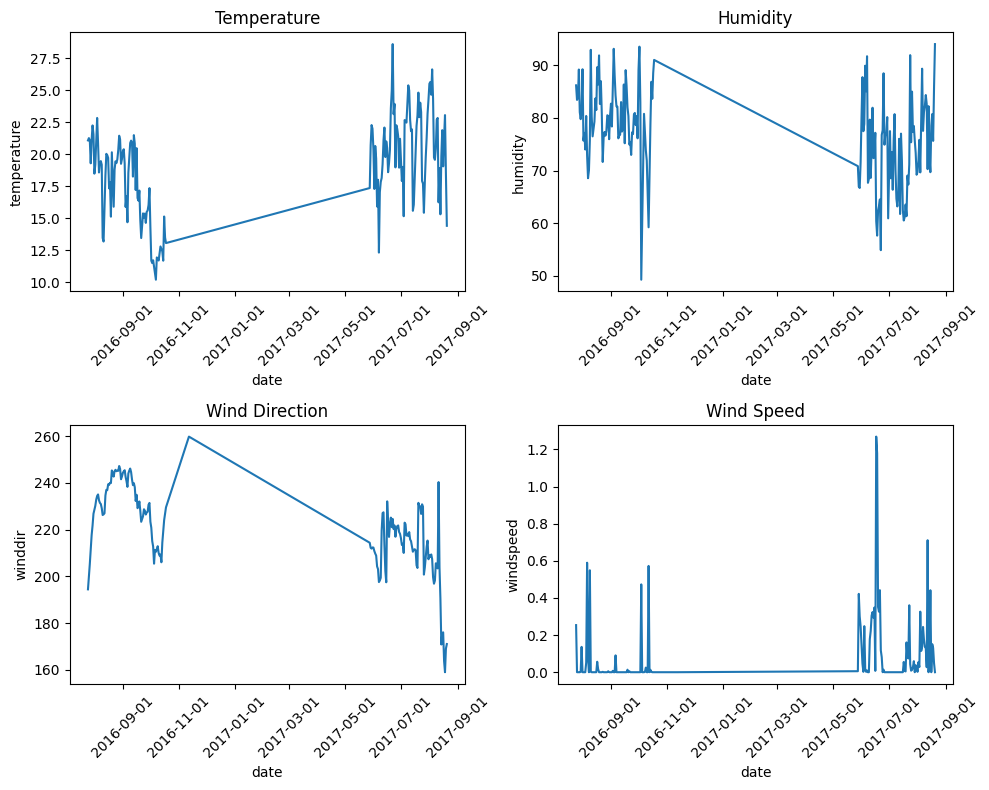

In [94]:
# Create a single subplot with a grid layout
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

# Plot each line plot in the grid layout
sns.lineplot(data=daily_data['temperature'], ax=axes[0, 0])
axes[0, 0].set_title('Temperature')

sns.lineplot(data=daily_data['humidity'], ax=axes[0, 1])
axes[0, 1].set_title('Humidity')

sns.lineplot(data=daily_data['winddir'], ax=axes[1, 0])
axes[1, 0].set_title('Wind Direction')

sns.lineplot(data=daily_data['windspeed'], ax=axes[1, 1])
axes[1, 1].set_title('Wind Speed')

# Format X-axis labels
date_form = DateFormatter("%Y-%m-%d")
for ax in axes.flat:
    ax.xaxis.set_major_formatter(date_form)
    ax.tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

# Machine learning

In [109]:

daily_data.isnull().count()

temperature    392
humidity       392
windspeed      392
winddir        392
dtype: int64

In [110]:
len(daily_data)

392

### Splitting the dataset 80-20

In [96]:
from sklearn.model_selection import train_test_split
y = daily_data['temperature']
X = daily_data.drop(columns=['temperature'])

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [97]:
X.head(10)

,humidity,windspeed,winddir
date,,,
2016-07-25,86.176471,0.253623,194.405797
2016-07-26,83.406250,0.000000,199.739583
2016-07-27,83.885417,0.000000,205.260417
2016-07-28,89.177083,0.000000,211.739583
2016-07-29,81.094737,0.000000,217.642105
2016-07-30,79.760417,0.002083,221.708333
2016-07-31,81.500000,0.136458,226.770833
2016-08-01,89.229167,0.000000,228.395833
2016-08-02,75.687500,0.000000,230.166667


In [30]:
X_train.head(10)

,humidity,windspeed,winddir
date,,,
2017-04-09,NaN,NaN,NaN
2017-01-23,NaN,NaN,NaN
2017-01-13,NaN,NaN,NaN
2016-09-26,80.645833,0.000000,226.427083
2017-06-30,60.935897,0.000000,218.166667
2017-03-11,NaN,NaN,NaN
2017-06-19,62.322917,0.351042,222.302083
2017-08-09,82.270833,0.136458,205.239583
2017-04-29,NaN,NaN,NaN


In [98]:
X_train.isnull()

,humidity,windspeed,winddir
date,,,
2017-04-09,True,True,True
2017-01-23,True,True,True
2017-01-13,True,True,True
2016-09-26,False,False,False
2017-06-30,False,False,False
...,...,...,...
2016-10-04,False,False,False
2016-11-08,True,True,True
2017-04-21,True,True,True


In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error




model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print(mse)


ValueError: Input X contains NaN.
RandomForestRegressor does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values